In [19]:
# constants

#general strings
GEOM_COL_NAME = 'geometry'
PATH_COL_NAME = 'path'
TIF_SUFFIX = '.tif'
GEOJSON_SUFFIX = '.geojson'
CONST_CRS = "4326"
CRS_3857 = "3857"
# SUFFIX_FOR_TIF_FOLDER = "/*.TIF"
SUFFIX_FOR_TIF_FOLDER = "/*.tif"

LAYER_COL_NAME ='layer'

STR_MINX = 'minx'
STR_MINY = 'miny'
STR_MAXX = 'maxx'
STR_MAXY = 'maxy'

BUILDING_STR = "building"

In [20]:
# utils

import pandas as pd
import numpy as np
import rasterio
from rasterio.mask import mask
from rasterio.merge import merge
import geopandas as gpd
from shapely.geometry import box,Polygon
import glob
import warnings
from tqdm import tqdm
import pathlib
import os
import shutil

Functions

In [21]:
#|export


def calculate_buffer(
        gdf : gpd.GeoDataFrame , # buffer will be calculated for this geodataframe
        buffer_size : float , # buffer size in meters
        )->gpd.GeoDataFrame:
    """ 
    This function accepts a GeoDataFrame and a buffer size, processes the following steps:
    
    1. Finds the estimated UTM CRS for the GeoDataFrame's geographic extent.
    2. Reprojects the GeoDataFrame to the estimated UTM CRS.
    3. Calculates the buffer for each geometry in the GeoDataFrame using the specified buffer size.
    4. Reprojects the buffered GeoDataFrame back to the WGS84 (EPSG:4326) projection.
    
    Parameters:
    gdf (GeoDataFrame): The input GeoDataFrame with geometries in WGS84 (EPSG:4326) projection.
    buffer_size (float): The buffer size to apply to each geometry in the GeoDataFrame.
    
    Returns:
    GeoDataFrame: A new GeoDataFrame with buffered geometries reprojected back to WGS84 
    
    """
    
    estimated_utm = gdf.estimate_utm_crs() 
    gdf = gdf.to_crs(estimated_utm)

    gdf[GEOM_COL_NAME] = gdf.buffer(distance = buffer_size)

    gdf = gdf.to_crs(CONST_CRS)



In [22]:
#|export

def save_raster(
    img:np.ndarray , # ndarray image
    number_of_bands: int , #number of  bands
    transf:tuple ,#transform function of the raster
    paths:str ,#save path raster
    tiff_name:str ,#name of specific file
    crs_img:rasterio.crs.CRS,
    ):  
    
    '''
    Function to save raster in requested path

    '''

    savedir=pathlib.Path(paths)
    savedir.mkdir(parents=True,exist_ok=True)


    with rasterio.open(savedir /tiff_name, 
                                   'w',
                                   driver='COG',
                                   height=img.shape[1],
                                   width=img.shape[2],
                                   count=number_of_bands,
                                   dtype=img.dtype,
                                   crs=crs_img,
                                   nodata=None, # change if data has nodata value
                                   transform=transf) as dst:

            for n in np.arange(0,number_of_bands):
                  dst.write(img[n,:,:],int(n+1))   
                    
    return None

In [23]:
#|export

def get_list_of_rasters(
        raster_storage_path : str , #path where the rasters are stored.
        folder_suffix : str = SUFFIX_FOR_TIF_FOLDER
        ):
        """
        Retrieves the file paths of all images within a directory.

        Args:
        - raster_storage_path (str): The path of the directory containing rasters.

        Returns:
        - List[str]: A list containing the file paths of all images within the directory.

        """

        str_for_glob = raster_storage_path + folder_suffix

        list_of_rasters = glob.glob(rf"{str_for_glob}")

        if len(list_of_rasters)==0:
                warnings.warn("No rasters were found", UserWarning)

        else:
                print(f"Found {len(list_of_rasters)} rasters")
                

        return list_of_rasters

example

In [105]:
paths_rasters=get_list_of_rasters(
        raster_storage_path ="/home/jovyan/work/imagery/afghanistan/kandahar_13082025",
folder_suffix="/*.tif")

Found 66 rasters


In [ ]:
#|export

def raster_extent_to_vector(
        raster_path : str , # Path to the raster file for which we want to obtain its extent as a vector representation
        raster_crs : str = "4326", #crs , deafule is 4326
)-> gpd.GeoDataFrame:
        """
        This function takes a string path to a raster file, extract the extent as vector, and returns its extent as geodataframe.
    
        Parameters:
        raster_path (str): The file path to the raster file (e.g., .tif).
        
        Returns:
        GeoDataFrame: A tuple representing the extent of the raster data as geopandas
        """
        
        src = rasterio.open(raster_path)
        src_src=src.crs
        raster_extent = src.bounds

        polygon_gdf = gpd.GeoDataFrame(geometry = [box(*raster_extent)])
        polygon_gdf=polygon_gdf.set_crs(src_src)
        polygon_gdf = polygon_gdf.to_crs(raster_crs)

        return polygon_gdf

In [25]:
# raster_extent_to_vector(
#         raster_path ="/home/jovyan/work/imagery/myanamar/before/extract_tifs_before/24JAN28042722-S3DS_R1C1-050311774010_01_P001.TIF")

In [26]:
#|export

def many_rasters_to_vector_layer(
        path_to_rasters : str , #path to rasters layers
        to_dissolve : bool=False , # when set to true, the polygons of the geodataframe will be dissolved
        raster_crs : str = "4326", #crs , deafule is 4326 
        ):
        
        raster_files = get_list_of_rasters(path_to_rasters)
        print(f"found {len(raster_files)} rasters in path")

        print('Extracting rasters extent')
        collect_gdf = []
        
        for file in tqdm(raster_files):
            try:
                tmp_gdf = raster_extent_to_vector(raster_path = file,
                                                 raster_crs = raster_crs)
                tmp_gdf[PATH_COL_NAME] = file
                collect_gdf.append(tmp_gdf)
                # print(len(collect_gdf))
            except Exception as e:
                print(f"Error processing path: {file}")
                print(f"Exception: {e}")
                continue


        df = pd.concat(collect_gdf)
        gdf = gpd.GeoDataFrame(df,geometry=GEOM_COL_NAME)

        
        if to_dissolve:
                gdf = gdf.dissolve()
                

        return gdf

example

In [99]:
test= many_rasters_to_vector_layer(
    path_to_rasters=r"/home/jovyan/work/imagery/afghanistan/kandahar_13082025",
    raster_crs = "32641")


# test

Found 66 rasters
found 66 rasters in path
Extracting rasters extent


100%|██████████| 66/66 [00:00<00:00, 80.95it/s]


<AxesSubplot:>

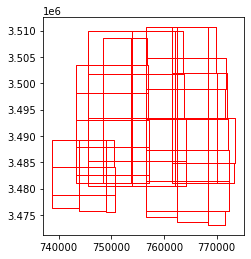

In [102]:
test.plot(facecolor="none",edgecolor="red" )

In [100]:
# test.to_file("/home/jovyan/work/imagery/afghanistan/tiles_32461.gpkg")

In [27]:
def get_raster_intersects_with_vector(rasters_path, polygon_path, dest_raster_path):

 
    print(f"Checking rasters in: {rasters_path}")
    # lst_paths = glob.glob(rasters_path + '/*.tif')
    lst_paths = glob.glob(rasters_path + SUFFIX_FOR_TIF_FOLDER)

    # SUFFIX_FOR_TIF_FOLDER
    # print(f"Raster files found: {len(lst_paths)}, Paths: {lst_paths}")
    
    polygon = gpd.read_file(polygon_path)
    print(f"Polygon CRS: {polygon.crs}")
    
    if not os.path.exists(dest_raster_path):
        os.makedirs(dest_raster_path)
        
    count, count_copy, count_clip = 0, 0, 0

    for path in lst_paths:
        try:
            print(f"\nProcessing: {path}")
            raster = rasterio.open(path)
            raster_crs = raster.crs
            print(f"raster crs: {raster_crs}")

            print("reproject polygon to raster crs")
            polygon = polygon.to_crs(raster_crs)

            print(f"Raster bounds: {raster.bounds}")

            # Get the raster's bounding box
            left, bottom, right, top = raster.bounds
            extent_raster = Polygon([(left, bottom), (right, bottom), (right, top), (left, top)])
            gdf_raster_extent = gpd.GeoDataFrame(geometry=[extent_raster], crs=polygon.crs)

            print(f"Polygon bounds: {polygon.total_bounds}")
            print(f"Raster extent bounds: {gdf_raster_extent.total_bounds}")
            print(f"Do they intersect? {polygon.geometry.intersects(gdf_raster_extent.unary_union).any()}")

            try:
                if polygon.geometry.intersects(gdf_raster_extent.unary_union).any():
                    print("Intersect found!")
                    file_name = os.path.basename(path)
                    file_dest_path = os.path.join(dest_raster_path, file_name)

                    if gdf_raster_extent.within(polygon.unary_union).any():
                        print("Raster is fully inside polygon, copying...")
                        shutil.copyfile(path, file_dest_path)
                        count_copy += 1
                    else:
                        print("Masking raster...")
                        masked_raster, transform = mask(raster, polygon.geometry, invert=False)

                        save_raster(
                            img=masked_raster,
                            number_of_bands=3,
                            transf=transform,
                            paths=dest_raster_path,
                            tiff_name=file_name,
                            crs_img=raster.crs
                        )
                        print(f"saved to : {dest_raster_path}//{file_name}")
                        count_clip += 1

                    count += 1

            except Exception as e:
                print(f"Error at: {path}, error: {e}")
                continue
        except Exception as e:
            print(f"Error at: {path}, error: {e}")
            continue           

    print(f"\nFinal Results:")
    print(f"Total rasters checked: {len(lst_paths)}")
    print(f"Total files copied: {count_copy}")
    print(f"Total files clipped: {count_clip}")


In [15]:
# get_raster_intersects_with_vector(rasters_path = "/home/jovyan/work/imagery/afghanistan/kandahar_13082025",
#                                       polygon_path = "/home/jovyan/work/imagery/afghanistan/kan_filter_tiles.gpkg",
#                                       dest_raster_path="/home/jovyan/work/imagery/afghanistan/dest")

In [28]:
#|export

def remove_duplicate_images(gdf_path : str, #path to geodataframe that contains tiles data  
                            path_imgs_to_remove : str , #path where images to remove are stored, considering the images have the same name 
                            ):
    
    gdf = gpd.read_file(gdf_path)

    #solve problem of order of same polygon that written in different direction
    # gdf[GEOM_COL_NAME] = gdf.normalize()

    #list of all paths 
    lst_all_paths = gdf[PATH_COL_NAME].tolist()

    #drop duplicated geometry
    gdf_drop_duplicates = gdf.drop_duplicates(subset=GEOM_COL_NAME,keep='first')

    #create list of non- duplicated

    lst_non_dupli = gdf_drop_duplicates[PATH_COL_NAME].tolist()

    # images to drop - images that are not in lst_non_dupli
    lst_to_remove = [item for item in lst_all_paths if item not in lst_non_dupli]

    # duplicates = gdf[gdf.duplicated(subset=GEOM_COL_NAME, keep=False)]

    # path_list = duplicates[PATH_COL_NAME].tolist()

    print(f"found {len(lst_to_remove)} duplicated rasters")

    names_of_tiles = [x.split("\\")[-1] for x in lst_to_remove]
    

    for name in names_of_tiles:
        path_to_remove = path_imgs_to_remove+"\\"+name
        os.remove(path_to_remove )


    return None

In [48]:
# remove_duplicate_images(gdf_path = "/home/jovyan/work/imagery/myanamar/before/before_tiles.gpkg",
#                             path_imgs_to_remove = "/home/jovyan/work/imagery/myanamar/before/filter",
#                             )

In [29]:
#|export

def clip_and_dissolve(
        path_preds: str , #path to predictions for validation
        path_clip_polygon: str, #path for polygons to clip the predictions
        path_dest : str , #path with destination wherer the clipped polygons will be saved
        ):

    gdf_preds = gpd.read_file(path_preds)

    #get all the masks 
    path_masks = glob.glob(path_clip_polygon+'\*.geojson')

    for path in path_masks:
        
        name = path.split('\\')[-1].split('.geojson')[0].split('CLIP_')[1]

        mask = gpd.read_file(path)
        gdf_masked = gdf_preds.clip(mask)
        print(f'len : {len(gdf_masked)}')

        # dissolved = gdf_masked.dissolve()

        # dissolved = dissolved.explode()


        gdf_masked.to_file(path_dest+'\\'+name+'.geojson')

        


    return path_masks

In [30]:
#|export

def merge_small_rasters(
        path_stored_rasters : str , #path where the rasters are saved
        file_dest_path : str , #destination path for results
        file_name : str = 'merged' , #name of the results file
        method : str ='max' , #method to be used for merge. 'max' is the deafult
        ):
        
        lst_rasters_paths = glob.glob(path_stored_rasters+'\*')
        rasters = [rasterio.open(path) for path in lst_rasters_paths][:50]

        merged_raster, transform = merge(rasters, method=method)


        save_raster(img = merged_raster,
                        number_of_bands = 3,
                        transf = transform,
                        paths = file_dest_path,
                        tiff_name = file_name,
                        crs_img = CONST_CRS)

        return merged_raster

In [31]:
#|export

def clip_with_mask_for_exaluation(
        path_predictions : str , #path for predictions 
        path_masks : str , #path where masks are stored
        dest : str , #path where to save the masked predictions
        ):
        
        if not os.path.exists(dest):
              os.makedirs(dest)

        preds_gdf =gpd.read_file(path_predictions)
        preds_gdf = preds_gdf.to_crs(CONST_CRS)

        lst_masks = glob.glob(path_masks+'\*.geojson')
        print(lst_masks)

        for mask in lst_masks:
               name = mask.split("\\")[-1].split('.')[0].split('_clip')[0]#.split('_val')[0]
               print(name)
               mask_gdf = gpd.read_file(mask)
               mask_gdf = mask_gdf.to_crs(CONST_CRS)

               clipped_gdf = gpd.clip(preds_gdf, mask_gdf)

               clipped_gdf.to_file(dest+"\\"+name+".geojson")
               print(f'saved to : {dest}\\{name}.geojson')



        return lst_masks

In [32]:
#TODO add the function to generate raster list instead of insert list
import os
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
import shutil

def reproject_rasters(
        lst_urls: list, #list of paths to rasters
        dest_crs: str, #destination crs, for example : 'EPSG:4326'
        local_save_path: str, #local_path to save the reprojected image
        # creds: str, #path to json file with credits to GCS
        # bucket_dest: str, #bucket where the reprojected imaegs should be stored
        # dest_path_bucket: str, #path to save the result images on GCS
        
        ):
        '''Based on this : https://hatarilabs.com/ih-en/how-to-reproject-single-and-multiple-rasters-with-python-and-rasterio-tutorial'''

        #define destination crs
        dstCrs = {'init': dest_crs}

        #iterate through list of urls to reproject
        for url in lst_urls:
              print('new loop')
              
              uniq_name=url.split('/')[-1]
              # print(uniq_name1)
            

            

#               #TODO: new name - with information about preprocess (4326 projected). TO BE CHANGED TO SOMETHING MORE GENERAL
#               lst_names=uniq_name1.split('/')[-1].split('.')
#               uniq_name=lst_names[0]+'.'+lst_names[1]+'.'+lst_names[2]+'.'+lst_names[3]+'.'+'projected_4326'+'.tif'

              print(f'unique id: {uniq_name}')
              srcRst = rasterio.open(url)
              #calculate transform array and shape of reprojected raster
              
              transform, width, height = calculate_default_transform(
                     srcRst.crs, dstCrs, srcRst.width, srcRst.height, *srcRst.bounds)
              
              #creating meta for the destination raster
              kwargs = srcRst.meta.copy()
              kwargs.update({
                     'crs': dstCrs,
                     'transform': transform,
                     'width': width,
                     'height': height
                     })
              
              #open destination raster
              print('openning new raster file for reprojected tiff')
              dstRst = rasterio.open(local_save_path+uniq_name, 'w', **kwargs)
              print(f'{local_save_path}/{uniq_name}/')
              #reproject and save raster band data
              for i in range(1, srcRst.count + 1):
                    reproject(
                           source=rasterio.band(srcRst, i),
                           destination=rasterio.band(dstRst, i),
                           #src_transform=srcRst.transform,
                           src_crs=srcRst.crs,
                           #    dst_transform=transform,
                           dst_crs=dstCrs,
                           resampling=Resampling.nearest,
                           driver='cog')
                    
              #   #close destination raster
              dstRst.close()

In [48]:
paths_rasters=get_list_of_rasters(
        raster_storage_path ="/home/jovyan/work/imagery/test_brian/option6/",
folder_suffix="/*.TIF")

Found 1 rasters


In [49]:
reproject_rasters(
        lst_urls=paths_rasters,
        dest_crs= 'EPSG:4326',
        local_save_path  ="/home/jovyan/work/imagery/test_brian_4326/option6/")

new loop
unique id: 24MAR18053043-S3DS-200009394566_01_P001.TIF
openning new raster file for reprojected tiff
/home/jovyan/work/imagery/test_brian_4326/option6//24MAR18053043-S3DS-200009394566_01_P001.TIF/


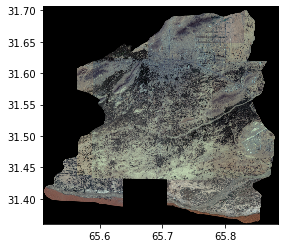

<AxesSubplot:>

In [121]:
from rasterio.plot import show
src = rasterio.open("/home/jovyan/work/imagery/afghanistan/NEW_MERGED4326merged.tif")
show(src.read(), transform=src.transform)                    

In [58]:
# import os
# import rasterio 
# from rasterio.warp import calculate_default_transform, reproject, Resampling
# import shutil

# def reproject_rasters(folder_path, target_crs, destination_folder):
#     """
#     Checks the projection of raster files in a folder, and reprojects them if necessary.

#     Parameters:
#     folder_path (str): Path to the folder containing raster files.
#     target_crs (str or dict): The target CRS (e.g., "EPSG:4326").
#     destination_folder (str): Path to the folder where reprojected rasters will be saved.
#     """
#     os.makedirs(destination_folder, exist_ok=True)  # Ensure destination folder exists

#     for filename in os.listdir(folder_path):
#         if filename.lower().endswith((".tif", ".tiff")):  # Case-insensitive check
#             raster_path = os.path.join(folder_path, filename)

#             with rasterio.open(raster_path) as src:
#                 src_crs = src.crs

#                 if src_crs != target_crs:
#                     print(f"Reprojecting {filename} from {src_crs} to {target_crs}")

#                     # Calculate transformation
#                     transform, width, height = calculate_default_transform(
#                         src_crs, target_crs, src.width, src.height, *src.bounds
#                     )
#                     print(f"new transform: {transform}")

#                     # Read the image data into memory to pass it to save_raster
#                     clipped_image = src.read()

#                     # Define metadata for the reprojected image
#                     clipped_transform = transform
#                     # file_name = f"reprojected_{os.path.splitext(filename)[0]}.tif"
#                     # file_dest_path = destination_folder

#                     file_name = raster_path.split("/")[-1].split(".")[0]
#                     file_dest_path =destination_folder + "/" 
#                     # Save the reprojected raster using save_raster
#                     save_raster(
#                         img=clipped_image,
#                         number_of_bands=src.count,
#                         transf=clipped_transform,
#                         paths=file_dest_path,
#                         tiff_name=file_name+".tif",
#                         crs_img=target_crs
#                     )
#                     print(f"Saved reprojected file: {file_dest_path}{file_name}")

#                 else:
#                     print(f"{filename} is already in the target CRS.")
#                     dest_path = os.path.join(destination_folder, os.path.splitext(filename)[0] + ".tif")
#                     shutil.copy2(raster_path, dest_path)
#                     print(f"Copied file to: {dest_path}")       
#     print("DONE!")

# # Example usage:
# # reproject_rasters("path/to/source_folder", "EPSG:4326", "path/to/destination_folder")


In [79]:
# # Example usage:
# reproject_rasters(folder_path = "/home/jovyan/work/imagery/afghanistan/merged_15082025", 
#                   target_crs = "EPSG:4326", 
#                   destination_folder ="/home/jovyan/work/imagery/afghanistan/MERGED4326")


Reprojecting merged.tif from EPSG:32641 to EPSG:4326
new transform: | 0.00, 0.00, 65.51|
| 0.00,-0.00, 31.71|
| 0.00, 0.00, 1.00|
Saved reprojected file: /home/jovyan/work/imagery/afghanistan/MERGED4326/merged
DONE!


In [15]:
import os
import glob
import rasterio
from rasterio.merge import merge
from tqdm import tqdm


def merge_rasters(input_folder: str, output_folder: str, output_name: str = "merged.tif"):
    """
    Merge all raster files in a folder and save as a single raster.

    Parameters:
        input_folder (str): Path where rasters are stored.
        output_folder (str): Path where the merged raster will be saved.
        output_name (str): Name of the merged raster file (default: 'merged.tif').
    """

    # Get all raster files (assuming GeoTIFFs)
    raster_files = glob.glob(os.path.join(input_folder, "*.tif"))

    if not raster_files:
        raise FileNotFoundError("No raster files found in the input folder.")

    src_files_to_mosaic = []

    # Open rasters with progress bar
    for raster in tqdm(raster_files, desc="Reading rasters", unit="file"):
        src_files_to_mosaic.append(rasterio.open(raster))

    # Merge rasters
    print("start mosaicking")
    mosaic, out_trans = merge(src_files_to_mosaic,method ='max')
    print("finish mosaic, saving results")
    # Copy metadata from the first raster
    out_meta = src_files_to_mosaic[0].meta.copy()
    out_meta.update({
        "driver": "GTiff",
        "height": mosaic.shape[1],
        "width": mosaic.shape[2],
        "transform": out_trans,
        "count": mosaic.shape[0]  # number of bands
    })

    # Ensure output folder exists
    os.makedirs(output_folder, exist_ok=True)

    # Save merged raster
    output_path = os.path.join(output_folder, output_name)
    with rasterio.open(output_path, "w", **out_meta) as dest:
        dest.write(mosaic)
    print(f"saved at {output_folder}/{output_name}")

    # Close raster sources
    for src in src_files_to_mosaic:
        src.close()

    return output_path


In [16]:
merge_rasters(input_folder="/home/jovyan/work/predictions/afghanistan/kandahar/B7_2025_HEATMAPS/heatmaps"
              , output_folder="/home/jovyan/work/predictions/afghanistan/kandahar/B7_2025_HEATMAPS/heatmaps_merged",
              output_name= "heatmap_merged.tif")


Reading rasters: 100%|██████████| 213564/213564 [11:39<00:00, 305.52file/s]


start mosaicking
finish mosaic, saving results
saved at /home/jovyan/workpredictions/afghanistan/kandahar/B7_2025_HEATMAPS/heatmaps_merged/heatmap_merged.tif


'/home/jovyan/workpredictions/afghanistan/kandahar/B7_2025_HEATMAPS/heatmaps_merged/heatmap_merged.tif'

THE FUNCTION THAT RUNS EVERTHING

In [55]:
#|export


def pre_process_high_res_imagery(
        rasters_path : str , # original path where the downloaded imagery is saved
        region_polygon_path : str , #polygon of the region
        destination_path : str , #destination path where the pre-process images to be saved
        dest_tiles_gpkg : str , #destination to store the geopackage with the tiles , for example "path/to/tiles/nangarhar.gpkg"
        ):
        # try:
        get_raster_intersects_with_vector(rasters_path = rasters_path,
                                               polygon_path = region_polygon_path,
                                               dest_raster_path = destination_path)

        # save only rasters that intersect with the region polygon , clip if needed
        tiles_gdf = many_rasters_to_vector_layer(path_to_rasters=destination_path,
                                          to_dissolve=False)
        tiles_gdf.to_file(dest_tiles_gpkg)


        remove_duplicate_images(gdf_path = dest_tiles_gpkg,  
                                     path_imgs_to_remove  = destination_path)

        tiles_gdf = many_rasters_to_vector_layer(path_to_rasters=destination_path,
                                          to_dissolve=False)
        tiles_gdf.to_file(dest_tiles_gpkg)
#         except Exception as e:
#             print(e)
#             print("continue!")
            
#         print("Done with all items!")
            


        return None
        

In [57]:
pre_process_high_res_imagery(
        rasters_path = r"/home/jovyan/work/imagery/afghanistan/kandahar_13082025",
        region_polygon_path = r"/home/jovyan/work/imagery/afghanistan/geom.gpkg",
        destination_path =r"/home/jovyan/work/imagery/afghanistan/kandahar15082025_32461.gpkg",
        dest_tiles_gpkg  = r"/home/jovyan/work/imagery/afghanistan/kandahar_clean1.gpkg")

Checking rasters in: /home/jovyan/work/imagery/afghanistan/kandahar_13082025
Polygon CRS: epsg:4326

Processing: /home/jovyan/work/imagery/afghanistan/kandahar_13082025/25JUL29062632-S3DS_R1C2-200009194726_01_P001.tif
raster crs: EPSG:32641
reproject polygon to raster crs
Raster bounds: BoundingBox(left=753845.0606950001, bottom=3501722.266109, right=762092.0617830001, top=3509969.267197)
Polygon bounds: [ 738727.387856 3473095.853344  773420.913486 3510644.801058]
Raster extent bounds: [ 753845.060695 3501722.266109  762092.061783 3509969.267197]
Do they intersect? True
Intersect found!
Masking raster...
saved to : /home/jovyan/work/imagery/afghanistan/kandahar15082025_32461.gpkg//25JUL29062632-S3DS_R1C2-200009194726_01_P001.tif

Processing: /home/jovyan/work/imagery/afghanistan/kandahar_13082025/25JUL29062632-S3DS_R1C3-200009194726_01_P001.tif
raster crs: EPSG:32641
reproject polygon to raster crs
Raster bounds: BoundingBox(left=762092.0617830001, bottom=3501722.266109, right=763533.

 14%|█▎        | 9/66 [00:00<00:00, 88.87it/s]

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16


 29%|██▉       | 19/66 [00:00<00:00, 92.24it/s]

17
18
19


...

44
45
46
47
48
49
50
51
52
53
54
55
56
57
58


 89%|████████▉ | 59/66 [00:00<00:00, 91.15it/s]

59
60
61
62
63


100%|██████████| 66/66 [00:00<00:00, 91.24it/s]
/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


64
65
66


In [17]:
import rasterio
import geopandas as gpd
from rasterio.mask import mask

# Input files
raster_path = "/home/jovyan/work/predictions/afghanistan/kandahar/B7_2025_HEATMAPS/merged/heatmap_merged.tif"
gpkg_path = "/home/jovyan/work/predictions/afghanistan/kandahar/B7_2025_HEATMAPS/merged/test_clip.gpkg"
# layer_name = "/home/jovyan/work/test"  # change if needed
output_path = "/home/jovyan/work/predictions/afghanistan/kandahar/B7_2025_HEATMAPS/merged/clip.tif"

# Read the clipping polygon
gdf = gpd.read_file(gpkg_path)

# Reproject polygon to match raster CRS
with rasterio.open(raster_path) as src:
    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    # Extract geometry in GeoJSON format
    print("extracting geom")
    geoms = [feature["geometry"] for feature in gdf.__geo_interface__["features"]]

    # Clip raster with polygon
    print("masking")

    out_image, out_transform = mask(src, geoms, crop=True)
    out_meta = src.meta.copy()
    print("finish m sk")

print("saving")

# Update metadata
out_meta.update({
    "driver": "GTiff",
    "height": out_image.shape[1],
    "width": out_image.shape[2],
    "transform": out_transform
})


# Save clipped raster
with rasterio.open(output_path, "w", **out_meta) as dest:
    dest.write(out_image)

print(f"Clipped raster saved to: {output_path}")


extracting geom
masking
finish m sk
saving
Clipped raster saved to: /home/jovyan/work/predictions/afghanistan/kandahar/B7_2025_HEATMAPS/merged/clip.tif


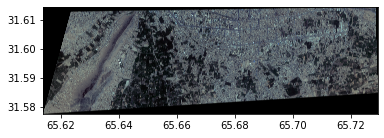

<AxesSubplot:>

In [124]:
from rasterio.plot import show
src = rasterio.open("/home/jovyan/work/imagery/afghanistan/clipped_raster.tif")
show(src.read(), transform=src.transform)                    

In [74]:
import os
import glob
import rasterio
from rasterio.merge import merge
from tqdm import tqdm


def merge_rasters(input_folder: str, output_folder: str, output_name: str = "merged.tif"):
    """
    Merge all raster files in a folder and save as a single raster.

    Parameters:
        input_folder (str): Path where rasters are stored.
        output_folder (str): Path where the merged raster will be saved.
        output_name (str): Name of the merged raster file (default: 'merged.tif').
    """

    # Get all raster files (assuming GeoTIFFs)
    raster_files = glob.glob(os.path.join(input_folder, "*.tif"))

    if not raster_files:
        raise FileNotFoundError("No raster files found in the input folder.")

    src_files_to_mosaic = []

    # Open rasters with progress bar
    for raster in tqdm(raster_files, desc="Reading rasters", unit="file"):
        src_files_to_mosaic.append(rasterio.open(raster))

    # Merge rasters
    print("start mosaicking")
    mosaic, out_trans = merge(src_files_to_mosaic)
    print("finish mosaic, saving results")
    # Copy metadata from the first raster
    out_meta = src_files_to_mosaic[0].meta.copy()
    out_meta.update({
        "driver": "GTiff",
        "height": mosaic.shape[1],
        "width": mosaic.shape[2],
        "transform": out_trans,
        "count": mosaic.shape[0]  # number of bands
    })

    # Ensure output folder exists
    os.makedirs(output_folder, exist_ok=True)

    # Save merged raster
    output_path = os.path.join(output_folder, output_name)
    with rasterio.open(output_path, "w", **out_meta) as dest:
        dest.write(mosaic)
    print(f"saved at {output_folder}/{output_name}")

    # Close raster sources
    for src in src_files_to_mosaic:
        src.close()

    return output_path


In [75]:
merge_rasters(input_folder="/home/jovyan/work/imagery/afghanistan/kandahar15082025_32461"
              , output_folder="/home/jovyan/work/imagery/afghanistan/merged_15082025",
              output_name= "merged.tif")


Reading rasters: 100%|██████████| 66/66 [00:00<00:00, 401.24file/s]


start mosaicking
finish mosaic, saving results
saved at /home/jovyan/work/imagery/afghanistan/merged_15082025/merged.tif


'/home/jovyan/work/imagery/afghanistan/merged_15082025/merged.tif'

In [77]:
src=rasterio.open("/home/jovyan/work/imagery/afghanistan/merged_15082025/merged.tif")
arr=src.read()
import matplotlib.pyplot as plt

plt.imshow(arr[0])

In [ ]:
from rasterio.plot import show
r = src[0]
g = src[1]
b = src.read[2]

rgb = (r, g, b)
show(rgb, transform=src.transform, title="RGB Composite")

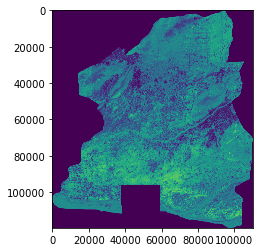

In [78]:
import matplotlib.pyplot as plt

plt.imshow(arr[0])

In [18]:
import geopandas as gpd

gdf = gpd.read_file("/home/jovyan/work/predictions/afghanistan/kandahar/B7_2025_HEATMAPS/preds/preds_B7_hm.geojson")
gdf.to_file("/home/jovyan/work/predictions/afghanistan/kandahar/B7_2025_HEATMAPS/preds/preds_B7_hm.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


In [56]:
import rasterio

src = rasterio.open("/home/jovyan/work/imagery/test_brian/run2/Maxar-Imagery_wms_geotiff/Maxar-Imagery_wms_geotiff.tif")

In [57]:
src.read().shape

(4, 4000, 4000)